
# Real Estate Housing Price Prediction Using Ridge and Lasso Regression

## 1. Project Overview

This project focuses on predicting median house values using the California Housing dataset and machine learning regression techniques.

## 2. Objective

- Analyze and preprocess the housing dataset.
- Handle missing values and create interaction features.
- Build an OLS Linear Regression baseline model.
- Implement Ridge and Lasso Regression.
- Tune model hyperparameters using GridSearchCV.
- Evaluate models using RMSE, MAE, and R² score.
- Visualize prediction performance and residuals.

## 3. Dataset Description

The California Housing dataset contains information about housing districts, including median income, housing age, number of rooms, bedrooms, population, occupancy, geographical coordinates, and median house value.

The target variable is `median_house_value`.

## 4. Tools and Libraries

- Python
- Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 5. Methodology

1. Load and explore the dataset.
2. Handle missing values.
3. Perform correlation analysis.
4. Create interaction features.
5. Encode categorical variables.
6. Split data into training and testing sets.
7. Scale numerical features.
8. Train OLS, Ridge, and Lasso models.
9. Tune Ridge and Lasso using GridSearchCV.
10. Compare models and visualize results.


In [21]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the California Housing dataset
df = pd.read_csv("california_housing.csv")

# Display the first five rows
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [22]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names and data types
print("\nDataset Information:")
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape: (20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
med

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [23]:

# Check missing values before handling
print("Missing values before handling:")
print(df.isnull().sum())

# Fill missing numerical values with column medians
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

print("\nMissing values after handling:")
print(df.isnull().sum())


Missing values before handling:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after handling:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


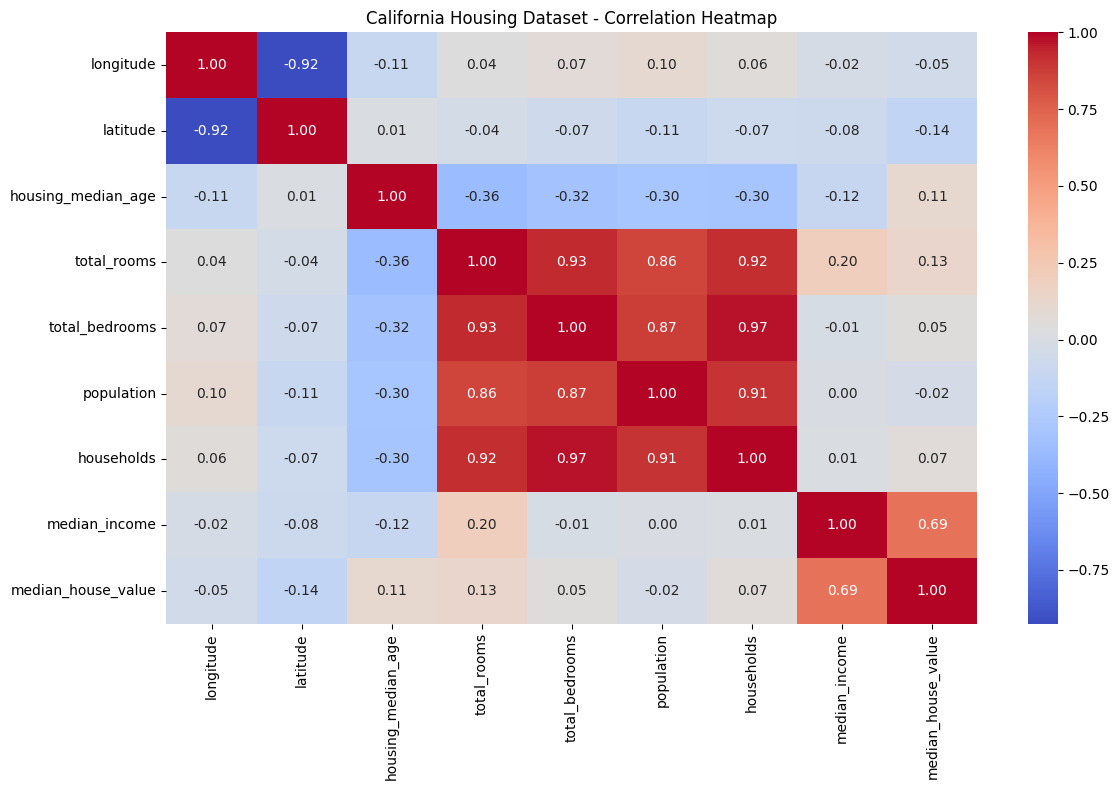

In [24]:

# Calculate correlations between numerical columns
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Plot the correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("California Housing Dataset - Correlation Heatmap")
plt.tight_layout()
plt.show()


In [25]:

# Create a copy of the cleaned dataset
df_model = df.copy()

# Create interaction features using actual column names
df_model["rooms_per_bedroom"] = (
    df_model["total_rooms"] / (df_model["total_bedrooms"] + 1e-6)
)

df_model["income_per_person"] = (
    df_model["median_income"] / (df_model["population"] + 1)
)

# Display the new features
print("New interaction features created!")

display(df_model[[
    "total_rooms",
    "total_bedrooms",
    "rooms_per_bedroom",
    "median_income",
    "population",
    "income_per_person"
]].head())

print("\nUpdated dataset shape:", df_model.shape)


New interaction features created!


,total_rooms,total_bedrooms,rooms_per_bedroom,median_income,population,income_per_person
0,880.0,129.0,6.821705,8.3252,322.0,0.025775
1,7099.0,1106.0,6.418626,8.3014,2401.0,0.003456
2,1467.0,190.0,7.721053,7.2574,496.0,0.014602
3,1274.0,235.0,5.421277,5.6431,558.0,0.010095
4,1627.0,280.0,5.810714,3.8462,565.0,0.006795



Updated dataset shape: (20640, 12)


In [26]:
# Check all column names in the dataset
print(df.columns.tolist())

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [27]:

# Convert the categorical column into numerical columns
df_model = pd.get_dummies(
    df_model,
    columns=["ocean_proximity"],
    drop_first=True,
    dtype=int
)

# Separate input features (X) and target (y)
X = df_model.drop(columns=["median_house_value"])
y = df_model["median_house_value"]

# Display the results
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nFirst 5 target values:")
display(y.head())


Features (X) shape: (20640, 14)
Target (y) shape: (20640,)

Feature columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_bedroom', 'income_per_person', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']

First 5 target values:


0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64

In [28]:

from sklearn.model_selection import train_test_split

# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (16512, 14)
Testing features: (4128, 14)
Training target: (16512,)
Testing target: (4128,)


In [29]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform both datasets
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Check the scaled data
print("Feature scaling completed successfully!")
print("\nScaled training data:")
display(X_train_scaled.head())

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Feature scaling completed successfully!

Scaled training data:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_bedroom,income_per_person,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,1.272587,-1.372811,0.348490,0.222569,0.211228,0.768276,0.322906,-0.326196,-0.003155,-0.204338,-0.680574,-0.015566,-0.355646,2.629758
8267,0.709162,-0.876696,1.618118,0.340293,0.593094,-0.098901,0.672027,-0.035843,-0.590312,-0.125695,-0.680574,-0.015566,-0.355646,2.629758
17445,-0.447603,-0.460146,-1.952710,-0.342597,-0.495226,-0.449818,-0.430461,0.144701,0.632760,-0.038799,-0.680574,-0.015566,-0.355646,2.629758
14265,1.232698,-1.382172,0.586545,-0.561490,-0.409306,-0.007434,-0.380587,-1.017864,-0.953192,-0.206867,-0.680574,-0.015566,-0.355646,2.629758
2271,-0.108551,0.532084,1.142008,-0.119565,-0.256559,-0.485877,-0.314962,-0.171488,0.458369,-0.064021,1.469348,-0.015566,-0.355646,-0.380263



Training data shape: (16512, 14)
Testing data shape: (4128, 14)


In [30]:

from sklearn.linear_model import LinearRegression

# Create and train the OLS model
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

# Make predictions on test data
y_pred_ols = ols_model.predict(X_test_scaled)

print("OLS Linear Regression model trained successfully!")
print("First 10 actual house prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted house prices:")
print(y_pred_ols[:10])


OLS Linear Regression model trained successfully!
First 10 actual house prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 predicted house prices:
[ 61602.55885683 107103.3270712  223700.47530694 258420.65141541
 258044.36749721 104618.46685945 309142.97739238 241996.18795808
 259188.2844371  421621.73449852]


In [31]:

from sklearn.linear_model import Ridge

# Create and train the Ridge Regression model
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_ridge = ridge_model.predict(X_test_scaled)

print("Ridge Regression model trained successfully!")

print("\nFirst 10 actual house prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted house prices:")
print(y_pred_ridge[:10])


Ridge Regression model trained successfully!

First 10 actual house prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 predicted house prices:
[ 61607.67606661 107061.80147669 223735.9312568  258426.91665665
 258009.24672462 104650.06029736 309122.20705734 241986.75836173
 259177.57028118 421612.10071047]


In [32]:

from sklearn.linear_model import Lasso

# Create and train the Lasso Regression model
lasso_model = Lasso(alpha=1.0, max_iter=10000)

lasso_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lasso = lasso_model.predict(X_test_scaled)

print("Lasso Regression model trained successfully!")

print("\nFirst 10 actual house prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted house prices:")
print(y_pred_lasso[:10])


Lasso Regression model trained successfully!

First 10 actual house prices:
[ 47700.  45800. 500001. 218600. 278000. 158700. 198200. 157500. 340000.
 446600.]

First 10 predicted house prices:
[ 61606.19540764 107092.01394198 223703.33427296 258425.32035395
 258030.19001497 104631.76002494 309135.61346744 241992.54609422
 259187.17558216 421617.27321438]


In [33]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Evaluate all three models
results = []

models_predictions = {
    "OLS Linear Regression": y_pred_ols,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso
}

for model_name, predictions in models_predictions.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))


Model Evaluation Results:


,Model,RMSE,MAE,R2 Score
0,OLS Linear Regression,71450.1521,51290.0046,0.6104
1,Ridge Regression,71447.0580,51287.5430,0.6105
2,Lasso Regression,71449.1640,51289.1288,0.6104


In [34]:

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

# Define alpha values to test
ridge_params = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

# Perform GridSearchCV
ridge_grid = GridSearchCV(
    Ridge(),
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["alpha"])
print("Best cross-validation RMSE:", -ridge_grid.best_score_)


Best Ridge alpha: 10
Best cross-validation RMSE: 68344.00230044725


In [35]:

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso

# Define alpha values to test
lasso_params = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

# Perform GridSearchCV
lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train_scaled, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_["alpha"])
print("Best cross-validation RMSE:", -lasso_grid.best_score_)


Best Lasso alpha: 100
Best cross-validation RMSE: 68338.32867080731


In [36]:

# Get the best models from GridSearchCV
best_ridge_model = ridge_grid.best_estimator_
best_lasso_model = lasso_grid.best_estimator_

# Make predictions using tuned models
y_pred_ridge_best = best_ridge_model.predict(X_test_scaled)
y_pred_lasso_best = best_lasso_model.predict(X_test_scaled)

# Evaluate all models
models = {
    "OLS Linear Regression": y_pred_ols,
    "Tuned Ridge Regression": y_pred_ridge_best,
    "Tuned Lasso Regression": y_pred_lasso_best
}

final_results = []

for name, predictions in models.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    final_results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

final_results_df = pd.DataFrame(final_results)

print("Final Model Comparison")
display(final_results_df.round(4))


Final Model Comparison


,Model,RMSE,MAE,R2 Score
0,OLS Linear Regression,71450.1521,51290.0046,0.6104
1,Tuned Ridge Regression,71420.1322,51266.2250,0.6107
2,Tuned Lasso Regression,71358.0846,51209.7579,0.6114



## 7. Actual vs. Predicted House Prices

This visualization compares the actual median house values with the values predicted by the tuned Ridge Regression model. Points closer to the diagonal reference line indicate more accurate predictions.


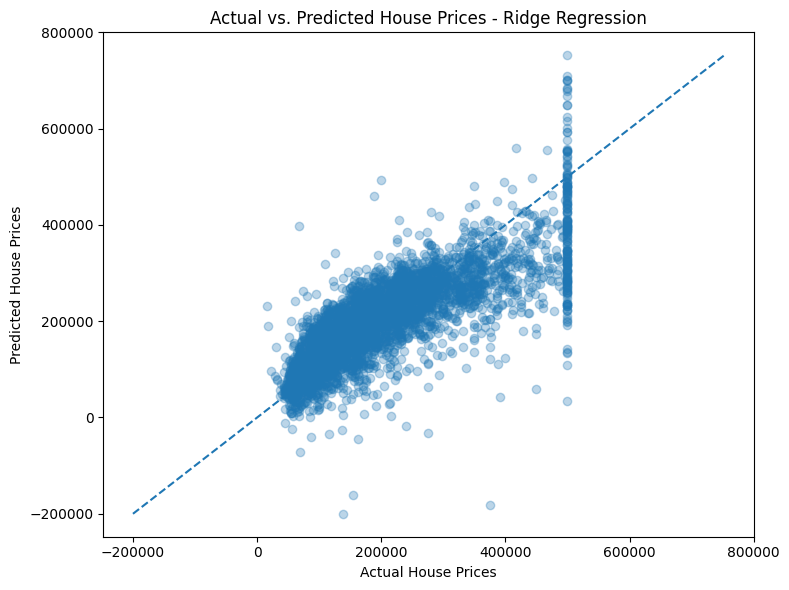

In [37]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_ridge_best,
    alpha=0.3
)

# Ideal prediction reference line
min_value = min(y_test.min(), y_pred_ridge_best.min())
max_value = max(y_test.max(), y_pred_ridge_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs. Predicted House Prices - Ridge Regression")
plt.tight_layout()
plt.show()



## 8. Residual Analysis

Residuals are the differences between actual and predicted house prices. A residual plot helps us identify patterns in prediction errors and assess model performance.


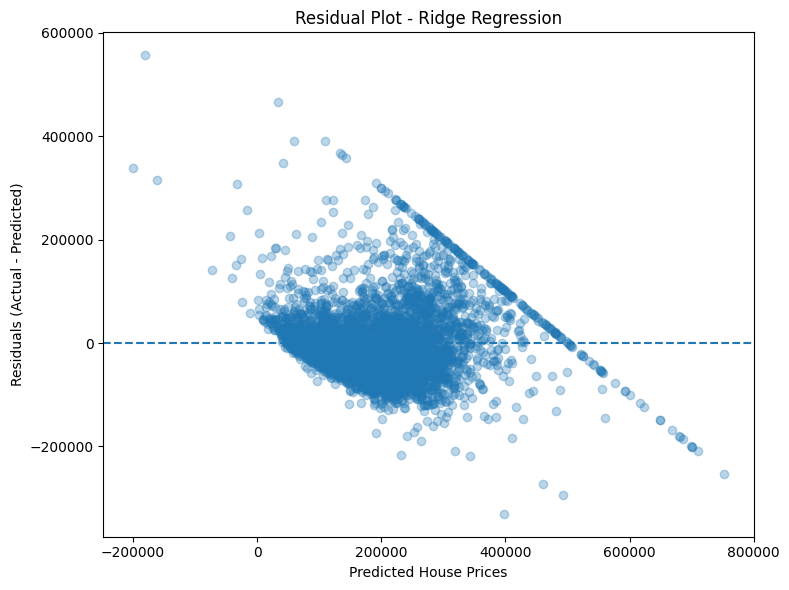

In [38]:

# Calculate residuals for the tuned Ridge model
residuals = y_test - y_pred_ridge_best

plt.figure(figsize=(8, 6))

plt.scatter(
    y_pred_ridge_best,
    residuals,
    alpha=0.3
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Ridge Regression")
plt.tight_layout()
plt.show()



## 9. Model Performance Comparison

This section compares OLS Linear Regression, tuned Ridge Regression, and tuned Lasso Regression using RMSE, MAE, and R² score.

Lower RMSE and MAE indicate smaller prediction errors, while a higher R² score indicates that the model explains more variation in house prices.


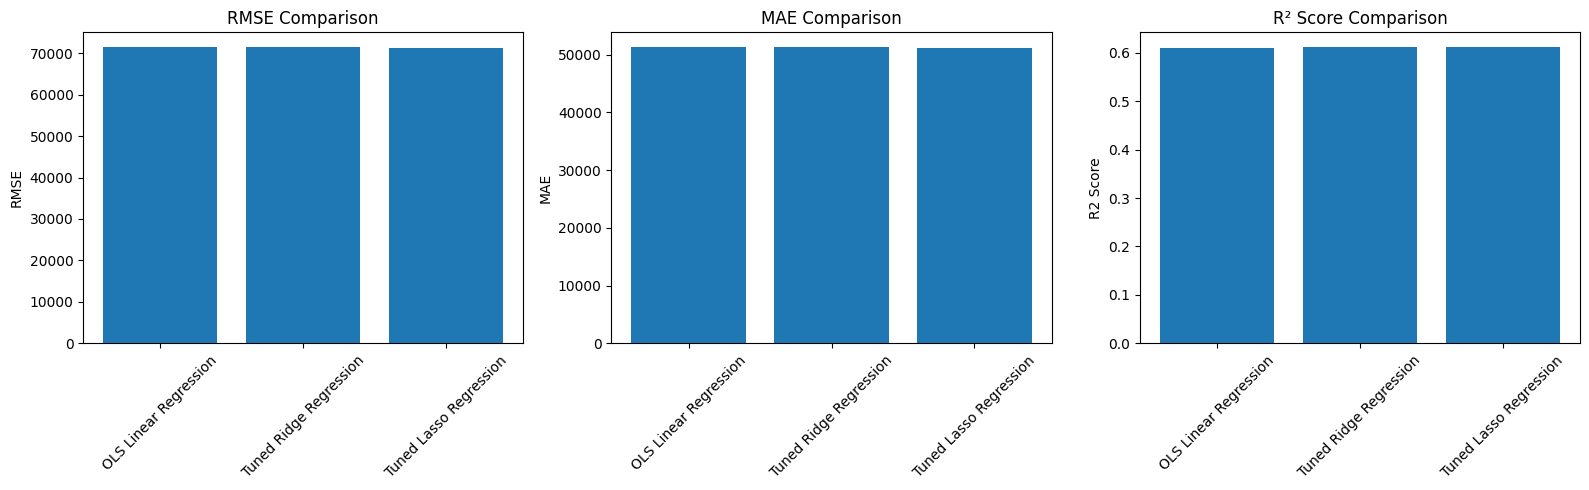

In [39]:

# Visual comparison of model evaluation metrics

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["RMSE", "MAE", "R2 Score"]
titles = ["RMSE Comparison", "MAE Comparison", "R² Score Comparison"]

for ax, metric, title in zip(axes, metrics, titles):
    ax.bar(final_results_df["Model"], final_results_df[metric])
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()



## 10. Conclusion

In this project, California housing data was analyzed and used to build house price prediction models.

The following regression models were implemented:

- Ordinary Least Squares (OLS) Linear Regression
- Ridge Regression with hyperparameter tuning using GridSearchCV
- Lasso Regression with hyperparameter tuning using GridSearchCV

Missing values were handled, interaction features were created, categorical data was encoded, and numerical features were scaled. Model performance was evaluated using RMSE, MAE, and R² score.

Actual vs. predicted values and residual plots were used to visualize prediction performance. The final model should be selected by comparing the evaluation metrics: lower RMSE and MAE indicate smaller errors, while a higher R² score indicates better explanatory performance.

This project demonstrates how regularization and hyperparameter tuning can be applied to a regression problem.
